<a href="https://colab.research.google.com/github/sentiashish/8_queen_problem_Simulation/blob/main/Experiment7_AnomalyDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 7 - Edge AI Application: Real-Time Vibration Anomaly Detection


TensorFlow: 2.21.0
Simulated stream: (400000, 3) | seconds: 400 | anomalous fraction (samples): 0.14


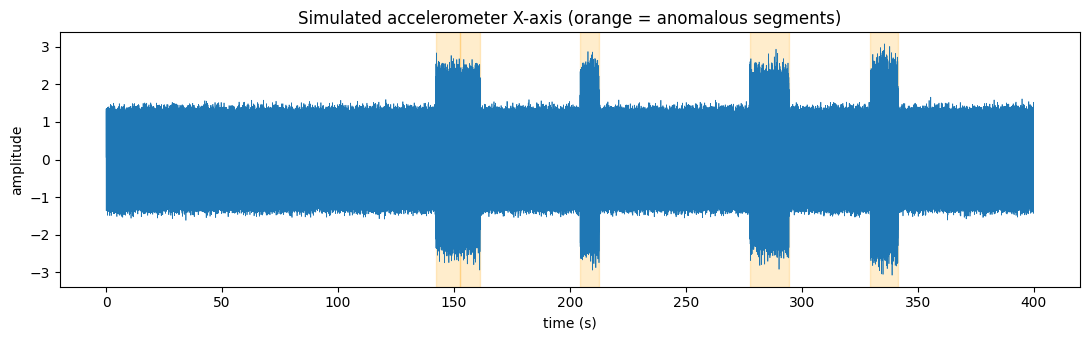

In [1]:
# CELL 1: setup + synthetic bearing-vibration stream
import os, time, json, numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

FS = 1000                 # simulated accelerometer sample rate (Hz)
STREAM_SECONDS = 400       # total simulated stream length
WIN_MS, HOP_MS = 200, 50   # window length / hop stride (manual's suggested values)
WIN_LEN = FS*WIN_MS//1000
HOP_LEN = FS*HOP_MS//1000

def gen_segment(n, anomaly=False, severity=0.0):
    """3-axis vibration segment. Normal = shaft rotation harmonics + noise.
    Anomaly = sparse high-frequency impulsive bursts + amplitude growth,
    the standard bearing-defect signature used in vibration fault-diagnosis literature."""
    t = np.arange(n) / FS
    axes = []
    for phase in (0.0, 2.09, 4.19):
        sig = (1.0*np.sin(2*np.pi*42*t+phase) + 0.35*np.sin(2*np.pi*84*t+phase)
               + 0.15*np.sin(2*np.pi*126*t+phase) + np.random.normal(0, 0.12, n))
        if anomaly:
            impulses = 0.9*severity*np.sin(2*np.pi*157*t+phase) * (np.random.rand(n) > 0.6)
            sig = sig*(1+0.6*severity) + impulses
        axes.append(sig)
    return np.stack(axes, axis=1)

def build_stream():
    n_total = STREAM_SECONDS*FS
    sig = np.zeros((n_total,3)); lab = np.zeros(n_total, dtype=int); segs=[]
    rng = np.random.default_rng(7); cursor=0
    while cursor < n_total:
        remain = n_total-cursor
        seg_len = min(int(rng.uniform(8,20)*FS), remain)
        is_anom = rng.random() < 0.22 and cursor > 20*FS
        sev = rng.uniform(0.5,1.0) if is_anom else 0.0
        sig[cursor:cursor+seg_len] = gen_segment(seg_len, is_anom, sev)
        lab[cursor:cursor+seg_len] = int(is_anom)
        segs.append((cursor, seg_len, is_anom)); cursor += seg_len
    return sig, lab, segs

signal, labels_per_sample, segments = build_stream()
print("Simulated stream:", signal.shape, "| seconds:", STREAM_SECONDS,
      "| anomalous fraction (samples):", round(labels_per_sample.mean(),3))

plt.figure(figsize=(11,3.5))
plt.plot(np.arange(len(signal))/FS, signal[:,0], linewidth=0.5)
for s,l,a in segments:
    if a: plt.axvspan(s/FS,(s+l)/FS, color="orange", alpha=0.2)
plt.title("Simulated accelerometer X-axis (orange = anomalous segments)")
plt.xlabel("time (s)"); plt.ylabel("amplitude"); plt.tight_layout(); plt.show()

In [2]:
# CELL 2: Task 1 - sliding window buffer + time-domain feature extraction
def extract_features(win):
    feats = []
    for c in range(win.shape[1]):
        x = win[:, c]
        rms = np.sqrt(np.mean(x**2))
        p2p = x.max() - x.min()
        std = x.std()
        mean_abs = np.mean(np.abs(x))
        m = np.mean(x); s = std if std > 1e-8 else 1e-8
        kurt = np.mean(((x-m)/s)**4) - 3
        crest = np.abs(x).max() / (rms + 1e-8)
        feats.extend([rms, p2p, std, mean_abs, kurt, crest])
    return np.array(feats)

def window_stream(signal, labels):
    X, y, starts = [], [], []
    for start in range(0, len(signal)-WIN_LEN+1, HOP_LEN):
        X.append(extract_features(signal[start:start+WIN_LEN]))
        y.append(int(labels[start:start+WIN_LEN].mean() > 0.5))
        starts.append(start)
    return np.array(X), np.array(y), np.array(starts)

t0 = time.time()
X, y, starts = window_stream(signal, labels_per_sample)
preprocess_ms = (time.time()-t0)*1000/len(X)
print("Windows:", X.shape, "| anomalous windows:", y.sum(), "/", len(y))
print(f"Avg feature-extraction time/window: {preprocess_ms:.4f} ms  (hop budget = {HOP_MS} ms)")

X_normal = X[y==0]
X_train_n, X_temp_n = train_test_split(X_normal, test_size=0.3, random_state=42)
X_val_n, X_calib_n = train_test_split(X_temp_n, test_size=0.5, random_state=42)
scaler = StandardScaler().fit(X_train_n)
X_train_s, X_val_s, X_calib_s, X_all_s = (scaler.transform(a) for a in (X_train_n, X_val_n, X_calib_n, X))
n_features = X.shape[1]
print("Feature vector length (6 stats x 3 axes):", n_features)
print("Train/val/calib normal windows:", X_train_s.shape[0], X_val_s.shape[0], X_calib_s.shape[0])

Windows: (7997, 18) | anomalous windows: 1122 / 7997
Avg feature-extraction time/window: 0.9264 ms  (hop budget = 50 ms)
Feature vector length (6 stats x 3 axes): 18
Train/val/calib normal windows: 4812 1031 1032


In [3]:
# CELL 3: Task 2 - Dense Autoencoder + Int8 quantization
inputs = keras.Input(shape=(n_features,))
h = keras.layers.Dense(12, activation="relu")(inputs)
h = keras.layers.Dense(6, activation="relu", name="bottleneck")(h)
h = keras.layers.Dense(12, activation="relu")(h)
outputs = keras.layers.Dense(n_features, activation="linear")(h)
autoencoder = keras.Model(inputs, outputs)
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()
history = autoencoder.fit(X_train_s, X_train_s, validation_data=(X_val_s, X_val_s),
                           epochs=60, batch_size=32, verbose=0)
print(f"Final train loss: {history.history['loss'][-1]:.4f}  | val loss: {history.history['val_loss'][-1]:.4f}")

autoencoder.save("autoencoder_fp32.h5")
fp32_kb = os.path.getsize("autoencoder_fp32.h5")/1024

def rep_data():
    for i in range(min(200, len(X_train_s))): yield [X_train_s[i:i+1].astype(np.float32)]
conv = tf.lite.TFLiteConverter.from_keras_model(autoencoder)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = rep_data
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8, tf.lite.OpsSet.TFLITE_BUILTINS]
conv.inference_input_type = tf.float32     # keep I/O float so reconstruction error stays meaningful
conv.inference_output_type = tf.float32
open("autoencoder_int8.tflite","wb").write(conv.convert())
int8_kb = os.path.getsize("autoencoder_int8.tflite")/1024
print(f"FP32 .h5: {fp32_kb:.2f} KB | Int8 .tflite: {int8_kb:.2f} KB | compression: {fp32_kb/int8_kb:.2f}x")

interp = tf.lite.Interpreter(model_path="autoencoder_int8.tflite"); interp.allocate_tensors()
in_det, out_det = interp.get_input_details()[0], interp.get_output_details()[0]
def tflite_infer(row):
    interp.set_tensor(in_det["index"], row.reshape(1,-1).astype(np.float32)); interp.invoke()
    return interp.get_tensor(out_det["index"])[0]

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 18)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │           228 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 6)              │            78 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 18)             │           234 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 624 (2.44 KB)

 Trainable params: 624 (2.44 KB)

 Non-trainable params: 0 (0.00 B)

Final train loss: 0.1691  | val loss: 0.1899
Saved artifact at '/tmp/tmphzixjug5'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 18), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 18), dtype=tf.float32, name=None)
Captures:
  138014107489424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138016476216208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138014107487504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138014107487120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138014107487888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138014107489232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138014107491728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138014107500176: TensorSpec(shape=(), dtype=tf.resource, name=None)
FP32 .h5: 40.19 KB | Int8 .tflite: 4.95 KB | compression: 8.11x


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [4]:
# CELL 4: Task 3 - threshold calibration + hysteresis trigger logic
recon_calib = np.array([tflite_infer(r) for r in X_calib_s])
mse_calib = np.mean((recon_calib - X_calib_s)**2, axis=1)
threshold = mse_calib.mean() + 3*mse_calib.std()
print(f"Calibration MSE (normal data only): mean={mse_calib.mean():.5f}  std={mse_calib.std():.5f}")
print(f"Threshold tau = mean + 3*std = {threshold:.5f}")

def hysteresis_trigger(flags, n_confirm=3):
    """Alarm only after n_confirm consecutive over-threshold windows (suppresses one-off spikes)."""
    out = np.zeros_like(flags); run = 0
    for i, f in enumerate(flags):
        run = run+1 if f else 0
        if run >= n_confirm: out[i] = 1
    return out

Calibration MSE (normal data only): mean=0.17216  std=0.11855
Threshold tau = mean + 3*std = 0.52781


[No hysteresis   ] acc=98.36%  precision=89.55%  recall=100.00%  F1=94.48%  FP=131  FN=0
[Hysteresis N=3  ] acc=99.77%  precision=98.42%  recall=100.00%  F1=99.20%  FP=18  FN=0
Confusion matrix with hysteresis [[TN, FP],[FN, TP]]:
 [[6857   18]
 [   0 1122]]
False alarms: 18 in 400s  ->  162.0 per hour (extrapolated)


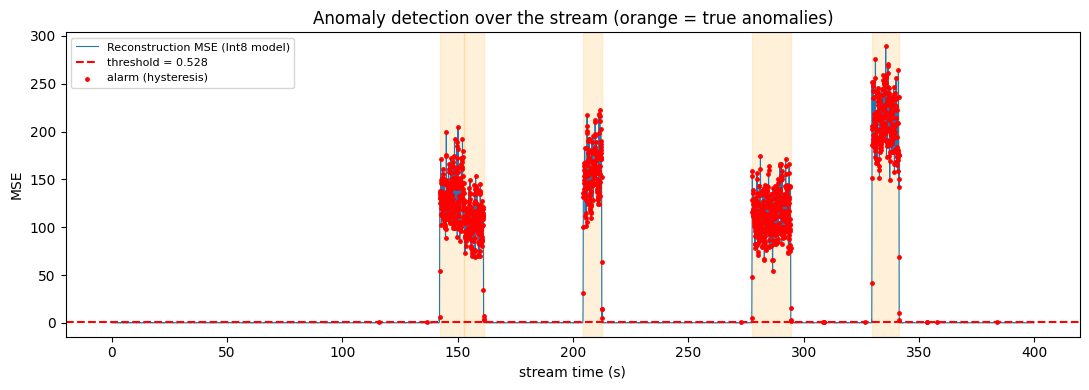

In [5]:
# CELL 5: Task 4 - run the whole stream window-by-window with the Int8 model
recon_all = np.array([tflite_infer(r) for r in X_all_s])
mse_all = np.mean((recon_all - X_all_s)**2, axis=1)
raw_flags = (mse_all > threshold).astype(int)
trig_flags = hysteresis_trigger(raw_flags, n_confirm=3)

def report(name, pred):
    cm = confusion_matrix(y, pred)
    print(f"[{name}] acc={accuracy_score(y,pred)*100:.2f}%  precision={precision_score(y,pred,zero_division=0)*100:.2f}%  "
          f"recall={recall_score(y,pred,zero_division=0)*100:.2f}%  F1={f1_score(y,pred,zero_division=0)*100:.2f}%  FP={cm[0,1]}  FN={cm[1,0]}")
    return cm
cm_raw  = report("No hysteresis   ", raw_flags)
cm_trig = report("Hysteresis N=3  ", trig_flags)
print("Confusion matrix with hysteresis [[TN, FP],[FN, TP]]:\n", cm_trig)
fp = int(cm_trig[0,1]); fp_per_hour = fp / (STREAM_SECONDS/3600)
print(f"False alarms: {fp} in {STREAM_SECONDS}s  ->  {fp_per_hour:.1f} per hour (extrapolated)")

tsec = starts/FS
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(tsec, mse_all, linewidth=0.8, label="Reconstruction MSE (Int8 model)")
ax.axhline(threshold, color="red", linestyle="--", label=f"threshold = {threshold:.3f}")
ax.scatter(tsec[trig_flags==1], mse_all[trig_flags==1], color="red", s=6, zorder=5, label="alarm (hysteresis)")
for s,l,a in segments:
    if a: ax.axvspan(s/FS,(s+l)/FS, color="orange", alpha=0.15)
ax.set_xlabel("stream time (s)"); ax.set_ylabel("MSE"); ax.set_title("Anomaly detection over the stream (orange = true anomalies)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

TASK 5: END-TO-END APPLICATION PROFILING
Chosen Application Domain           Anomaly Detection (3-axis vibration, bearing fault)
Window Length & Hop Stride          200 ms (200 samples) / 50 ms (50 samples)
Feature Dimension (Input Tensor)    18 (6 time-domain stats x 3 axes)
Model Parameters                    624
Quantized Model Size (Flash KB)     4.95 KB  (FP32 .h5: 40.19 KB)
SRAM estimate (KB)                  2.60 KB  (activations 264 B + window buffer 2400 B)
Preprocessing Overhead Latency      0.4822 ms
Model Inference Latency (ms)        0.0097 ms
Total End-to-End Latency (ms)       0.5082 ms  (hop budget 50 ms)
Detection Accuracy / F1 (%)         99.77% / 99.20%
False Positive Rate                 18 false alarms -> 162.0 per hour

Target boards (datasheet values):
  Arduino Nano 33 BLE Sense    Flash 1024 KB, SRAM 256 KB -> model 0.48% Flash, 1.02% SRAM
  ESP32                        Flash 4096 KB, SRAM 520 KB -> model 0.12% Flash, 0.50% SRAM
  Raspberry Pi 5               r

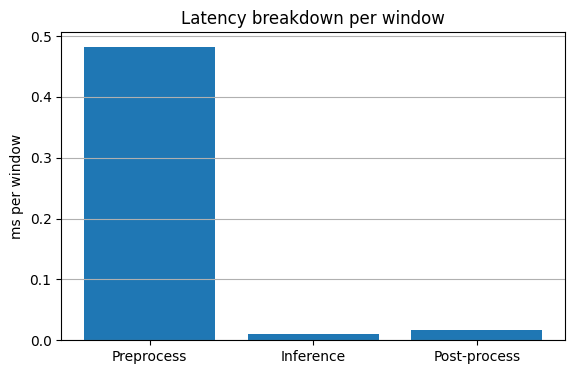

In [6]:
# CELL 6: Task 5 - end-to-end profiling table
N = 300
t0=time.perf_counter()
for i in range(N): extract_features(signal[starts[i]:starts[i]+WIN_LEN])
pre_ms=(time.perf_counter()-t0)*1000/N
tflite_infer(X_all_s[0])                                   # warm-up
t0=time.perf_counter()
for i in range(N): tflite_infer(X_all_s[i])
inf_ms=(time.perf_counter()-t0)*1000/N
t0=time.perf_counter()
for i in range(N):
    m = np.mean((X_all_s[i]-X_all_s[i])**2); _ = m > threshold      # MSE compare cost
post_ms=(time.perf_counter()-t0)*1000/N
total_ms = pre_ms+inf_ms+post_ms

# SRAM estimate: input + 3 hidden layers + output activations (float32) + the 200 ms raw window buffer
act_bytes = (n_features+12+6+12+n_features)*4
buffer_bytes = WIN_LEN*3*4
sram_kb = (act_bytes+buffer_bytes)/1024
print("="*72); print("TASK 5: END-TO-END APPLICATION PROFILING"); print("="*72)
rows = [
 ("Chosen Application Domain", "Anomaly Detection (3-axis vibration, bearing fault)"),
 ("Window Length & Hop Stride", f"{WIN_MS} ms ({WIN_LEN} samples) / {HOP_MS} ms ({HOP_LEN} samples)"),
 ("Feature Dimension (Input Tensor)", f"{n_features} (6 time-domain stats x 3 axes)"),
 ("Model Parameters", f"{autoencoder.count_params()}"),
 ("Quantized Model Size (Flash KB)", f"{int8_kb:.2f} KB  (FP32 .h5: {fp32_kb:.2f} KB)"),
 ("SRAM estimate (KB)", f"{sram_kb:.2f} KB  (activations {act_bytes} B + window buffer {buffer_bytes} B)"),
 ("Preprocessing Overhead Latency", f"{pre_ms:.4f} ms"),
 ("Model Inference Latency (ms)", f"{inf_ms:.4f} ms"),
 ("Total End-to-End Latency (ms)", f"{total_ms:.4f} ms  (hop budget {HOP_MS} ms)"),
 ("Detection Accuracy / F1 (%)", f"{accuracy_score(y,trig_flags)*100:.2f}% / {f1_score(y,trig_flags)*100:.2f}%"),
 ("False Positive Rate", f"{fp} false alarms -> {fp_per_hour:.1f} per hour"),
]
for k,v in rows: print(f"{k:36s}{v}")
print("\nTarget boards (datasheet values):")
for name, flash, sram in [("Arduino Nano 33 BLE Sense",1024,256),("ESP32",4096,520),("Raspberry Pi 5",None,None)]:
    if flash: print(f"  {name:28s} Flash {flash} KB, SRAM {sram} KB -> model {int8_kb/flash*100:.2f}% Flash, {sram_kb/sram*100:.2f}% SRAM")
    else:     print(f"  {name:28s} runs full Linux/Python - memory not a constraint for this model")
print("(Latency measured on the Colab CPU in Python - NOT on a microcontroller.)")

plt.figure(figsize=(6.5,4))
plt.bar(["Preprocess","Inference","Post-process"],[pre_ms,inf_ms,post_ms])
plt.ylabel("ms per window"); plt.title("Latency breakdown per window"); plt.grid(True,axis="y"); plt.show()

In [8]:
# CELL 7: where do the false alarms come from?
fp_idx = np.where((trig_flags==1) & (y==0))[0]
bounds = [(a/FS, (a+l)/FS) for a,l,an in segments if an]
def dist_to_boundary(t): return min(min(abs(t-b0), abs(t-b1)) for b0,b1 in bounds)
d = [dist_to_boundary(tsec[i] + WIN_MS/2000) for i in fp_idx]      # distance from window centre
near = sum(1 for x in d if x <= 0.25); far = len(d) - near
events = 1 + int(np.sum(np.diff(fp_idx) > 1)) if len(fp_idx) else 0
print("False-alarm windows:", len(fp_idx), "| merged into distinct events:", events)
print("Distance of each false alarm from the nearest true-anomaly boundary (s):", np.round(sorted(d),2).tolist())
print(f"Near a boundary (<= 0.25 s): {near}  |  Far from any boundary: {far}")

False-alarm windows: 18 | merged into distinct events: 13
Distance of each false alarm from the nearest true-anomaly boundary (s): [0.01, 0.04, 0.05, 0.05, 0.06, 0.09, 0.1, 3.08, 4.84, 5.25, 12.15, 12.2, 13.81, 14.36, 14.41, 16.35, 26.1, 42.4]
Near a boundary (<= 0.25 s): 7  |  Far from any boundary: 11
